In [1]:
import numpy as np
import pandas as pd
import cvxpy as cp
from dataclasses import dataclass
from power_system_data import PowerSystemData


In [2]:
data = PowerSystemData()


In [3]:
data = PowerSystemData(load_scenarios={
    'D1': {'S1': 3, 'S2': 10}, 'D2': {'S1': 1, 'S2': 1},
    'D3': {'S1': 18, 'S2': 15}, 'D4': {'S1': 15, 'S2': 20}})

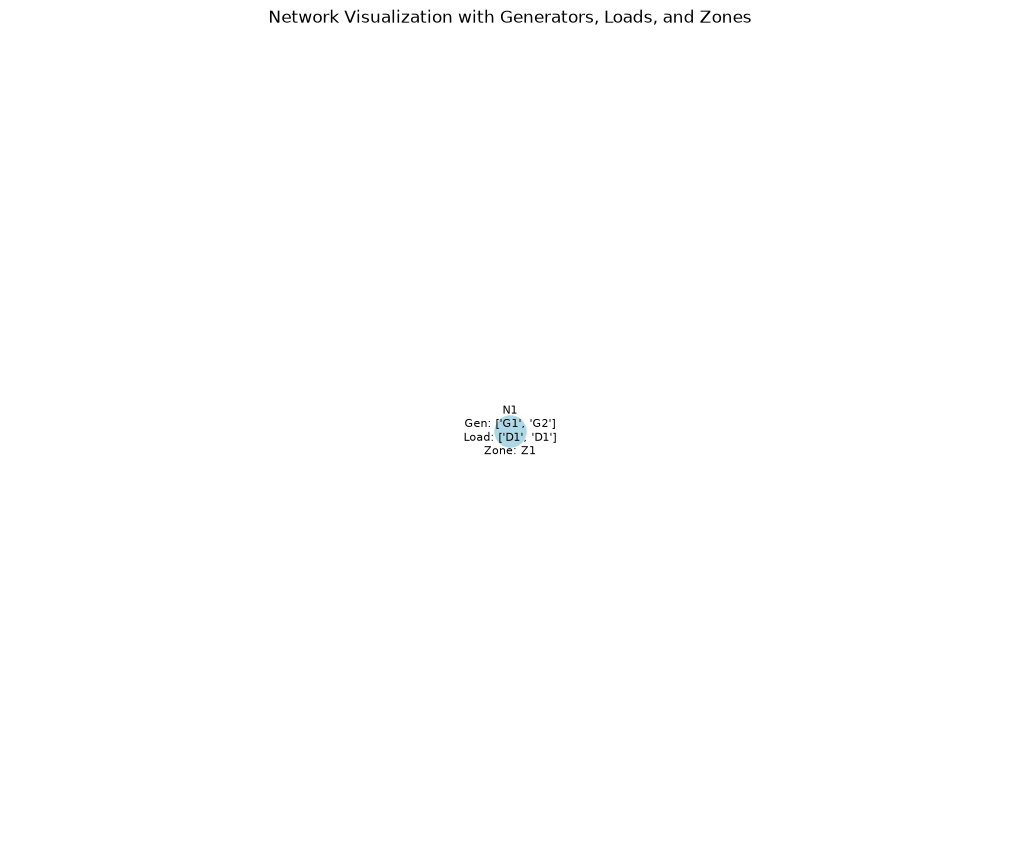

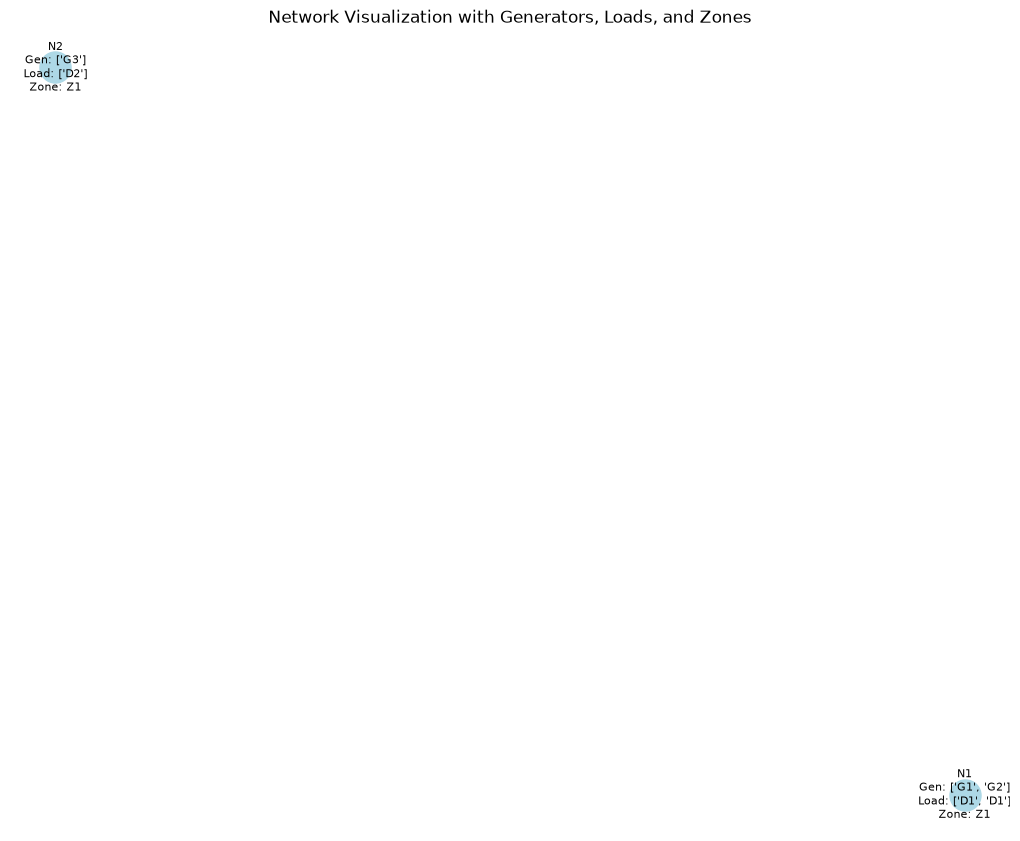

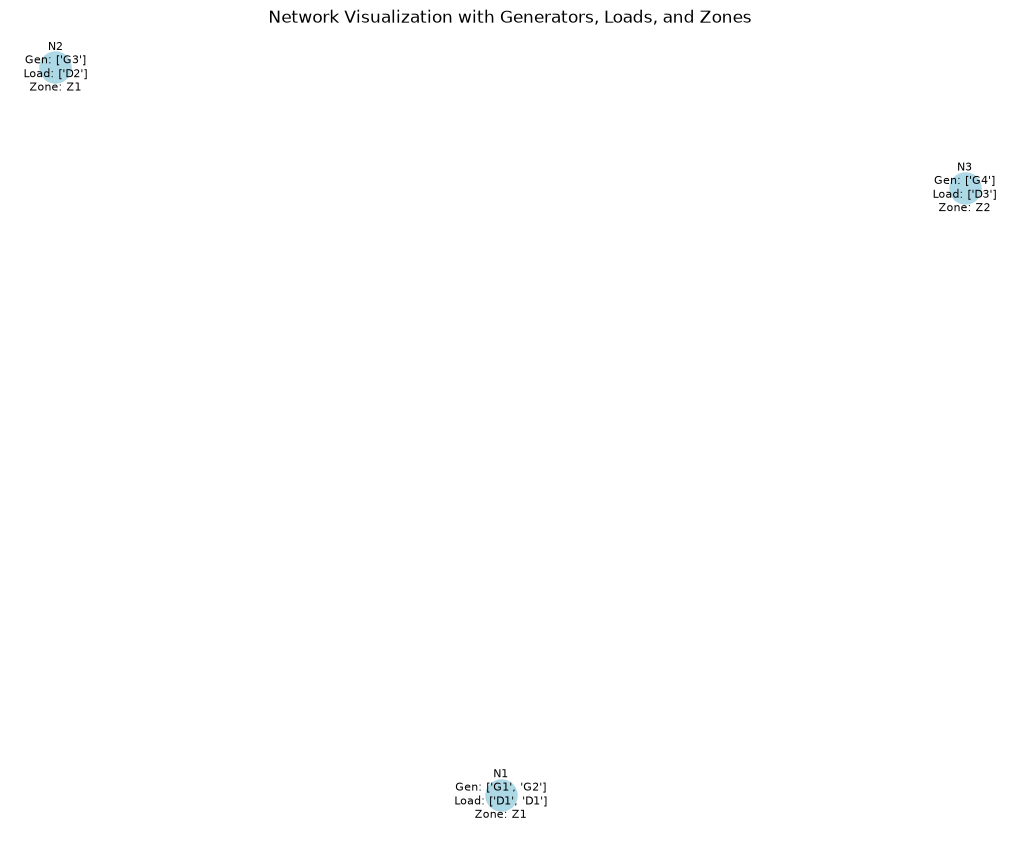

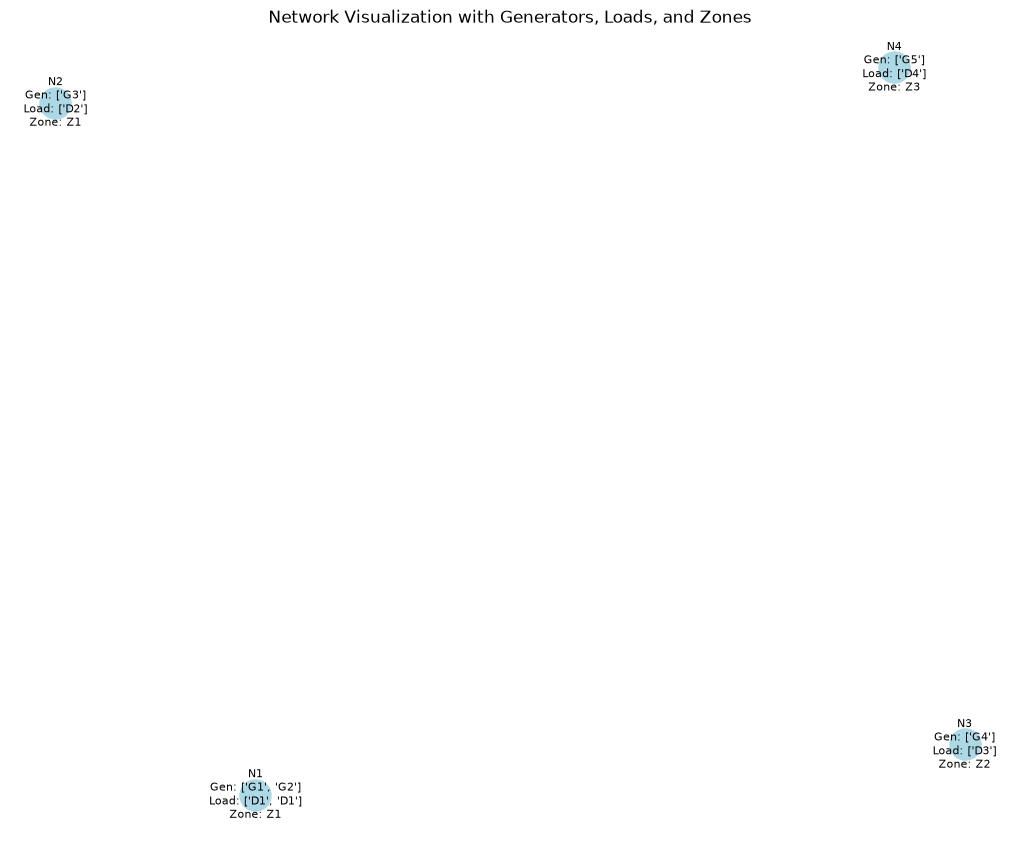

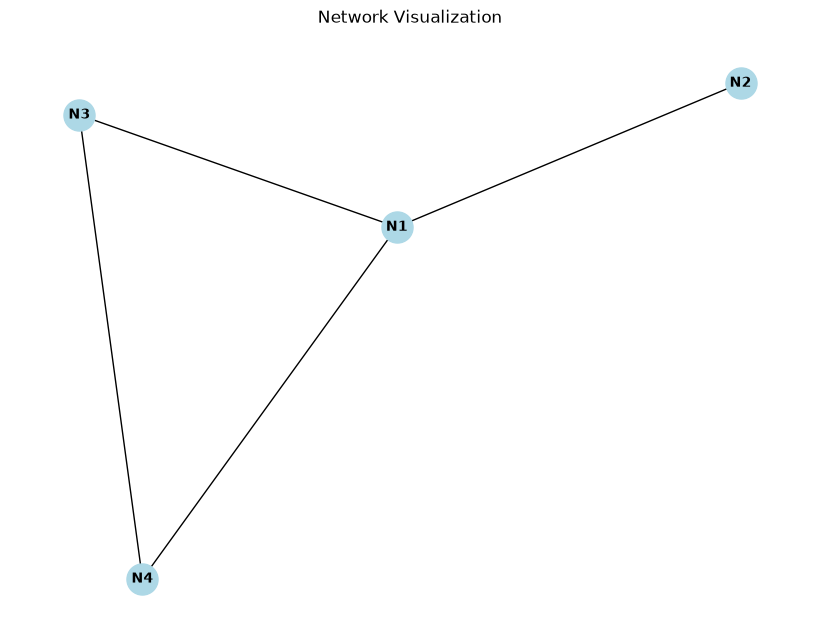

In [4]:
import networkx as nx

import matplotlib.pyplot as plt

# Create a graph
G = nx.Graph()

# Add nodes
for node in data.NODES:
    G.add_node(node)
    # Add generator presence
    if node in data.generators_per_node:
        for generator in data.generators_per_node[node]:
            G.nodes[node]['generators'] = G.nodes[node].get('generators', []) + [generator]
            # Add loads
            if node in data.loads_per_node:
                for load in data.loads_per_node[node]:
                    G.nodes[node]['loads'] = G.nodes[node].get('loads', []) + [load]

            # Add zones
            for zone, nodes in data.nodes_per_zone.items():
                if node in nodes:
                    G.nodes[node]['zone'] = zone

        # Update node labels to include generators, loads, and zones
        node_labels = {
            node: f"{node}\nGen: {G.nodes[node].get('generators', [])}\nLoad: {G.nodes[node].get('loads', [])}\nZone: {G.nodes[node].get('zone', '')}"
            for node in G.nodes
        }

        # Draw the graph with updated labels
        plt.figure(figsize=(10, 8))
        pos = nx.spring_layout(G)  # Positioning for better visualization
        nx.draw(G, pos, with_labels=False, node_color='lightblue', node_size=500, font_size=10, font_weight='bold')
        nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=8)
        plt.title("Network Visualization with Generators, Loads, and Zones")
        plt.show()

# Add edges
for node, connections in data.connections_per_node.items():
    for connection in connections:
        G.add_edge(node, connection)

# Draw the graph
plt.figure(figsize=(8, 6))
nx.draw(G, with_labels=True, node_color='lightblue', node_size=500, font_size=10, font_weight='bold')
plt.title("Network Visualization")
plt.show()

In [5]:
for key, value in data.__dict__.items():
    print(f"{key}: {value}")


N_GENERATORS: 5
N_LOADS: 4
N_NODES: 4
N_ZONES: 3
N_SCENARIOS: 2
N_RES: 2
GENERATORS: ['G1', 'G2', 'G3', 'G4', 'G5']
LOADS: ['D1', 'D2', 'D3', 'D4']
NODES: ['N1', 'N2', 'N3', 'N4']
ZONES: ['Z1', 'Z2', 'Z3']
SCENARIOS: ['S1', 'S2']
RENEWABLES: ['R1', 'R2']
S_BASE_MVA: 100.0
V_BASE_KV: {'N1': 230.0, 'N2': 230.0, 'N3': 230.0, 'N4': 230.0}
time_step: 1
slack_bus: N1
nodes_per_zone: {'Z1': ['N1', 'N2'], 'Z2': ['N3'], 'Z3': ['N4']}
connections_per_node: {'N1': ['N2', 'N3', 'N4'], 'N2': ['N1'], 'N3': ['N1', 'N4'], 'N4': ['N1', 'N3']}
generators_per_node: {'N1': ['G1', 'G2'], 'N2': ['G3'], 'N3': ['G4'], 'N4': ['G5']}
loads_per_node: {'N1': ['D1'], 'N2': ['D2'], 'N3': ['D3'], 'N4': ['D4']}
renewables_per_node: {'N1': [], 'N2': ['R1'], 'N3': [], 'N4': ['R2']}
gen_linear_cost_coeff: {'G1': 9, 'G2': 20, 'G3': 10, 'G4': 11, 'G5': 12}
gen_down_deviation_cost_coeff: {'G1': 2, 'G2': 0, 'G3': 2, 'G4': 2, 'G5': 2}
gen_up_deviation_cost_coeff: {'G1': 2, 'G2': 0, 'G3': 2, 'G4': 2, 'G5': 2}
gen_max_capacity

In [6]:
def solve_base_case(data: PowerSystemData, load=None, res=None, solver=cp.CLARABEL):
    """Day-ahead nodal dispatch (DC-OPF via PTDF) at a given load and renewable level.

    load: vector over data.LOADS;      defaults to data.expected_DA_load_vec.
    res:  vector over data.RENEWABLES; defaults to data.expected_DA_res_vec.
    """
    d = data.expected_DA_load_vec if load is None else np.asarray(load, float)
    r = data.expected_DA_res_vec if res is None else np.asarray(res, float)

    g = cp.Variable(len(data.GENERATORS))                # generator output
    C = cp.Variable(len(data.RENEWABLES))                # renewable curtailment
    P = cp.Variable(len(data.NODES))                     # nodal net injection
    f = cp.Variable(len(data.lines))                     # line flows

    nodal_balance = P == data.M_ng @ g + data.M_nr @ (r - C) - data.M_nd @ d   # G + r - C - d = P
    cons = [nodal_balance,
            f == data.PTDF @ P,
            cp.sum(P) == 0,
            g >= data.gen_min_vec, g <= data.gen_max_vec,
            C >= 0, C <= r,
            f <= data.line_cap_vec, f >= -data.line_cap_vec]
    prob = cp.Problem(cp.Minimize(data.gen_cost_vec @ g
                                  + data.res_curtailment_cost_vec @ C), cons)
    prob.solve(solver=solver)
    assert prob.status == cp.OPTIMAL, f"base case: {prob.status}"

    P_bc = P.value
    return dict(g=pd.Series(g.value, index=data.GENERATORS),
                C=pd.Series(C.value, index=data.RENEWABLES),
                P=pd.Series(P_bc, index=data.NODES),
                f=pd.Series(f.value, index=data.lines),
                NP=pd.Series(data.M_zn @ P_bc, index=data.ZONES),   # zonal net position
                LMP=pd.Series(nodal_balance.dual_value, index=data.NODES),  # nodal price
                cost=prob.value)

In [7]:
bc = solve_base_case(data)
for k, v in bc.items():
    print(f"{k}:\n{v}\n")

g:
G1    2.000000e+01
G2    1.585679e-10
G3    2.200000e+00
G4    4.600000e+00
G5    4.421403e-09
dtype: float64

C:
R1    1.004014e-10
R2    1.885659e-10
dtype: float64

P:
N1    14.2
N2    10.0
N3   -12.2
N4   -12.0
dtype: float64

f:
(N1, N2)   -10.000000
(N1, N3)    12.133333
(N1, N4)    12.066667
(N3, N4)    -0.066667
dtype: float64

NP:
Z1    24.2
Z2   -12.2
Z3   -12.0
dtype: float64

LMP:
N1    11.0
N2    10.0
N3    11.0
N4    11.0
dtype: float64

cost:
252.6000000107648



## Stage 1 outputs: flow-based parameters

Every line is monitored in both directions ($ stacks a $+$ and a 569Xl$ row per line,  = 2L$ rows):

65999\mathrm{zPTDF} = S\,\mathrm{PTDF}\,\mathrm{GSK} \qquad (J \times Z)65999

65999F_0 = S f^{bc} - \mathrm{zPTDF}\, NP^{bc} \quad \text{(flow at zero net positions)}65999

65999\mathrm{RAM}^{DA}_j = \max\big(\mathrm{minRAM}\,\bar f_j,\ \bar f_j - \mathrm{FRM}_j - \mathrm{FAV}_j - F_{0,j}\big), \qquad \mathrm{minRAM} = 0.7,\ \mathrm{FRM} = \mathrm{FAV} = 065999

A line is a CNE if $\max_{A \ne B} |\mathrm{zPTDF}_{j,A} - \mathrm{zPTDF}_{j,B}| \ge 5\%$. Only CNE rows go to the DA market.

In [8]:
def flow_based_parameters(data: PowerSystemData, bc, min_ram=0.7, frm=0.0, fav=0.0,
                          cne_threshold=0.05):
    """Stage 1 outputs passed to DA: zPTDF, F0, RAM^DA and the CNE selection.

    Every line is monitored in both directions: S stacks a +row and a -row per line (J = 2L).
    """
    L = len(data.lines)
    S = np.kron(np.eye(L), np.array([[1.0], [-1.0]]))           # (2L x L)
    labels = [f"{n}->{m}" if k == 0 else f"{m}->{n}"
              for (n, m) in data.lines for k in (0, 1)]
    f_max = np.abs(S) @ data.line_cap_vec                          # limit per direction

    zPTDF = S @ data.PTDF @ data.GSK                               # (J x Z)
    F0 = S @ bc['f'].values - zPTDF @ bc['NP'].values             # flow at zero net positions
    RAM = np.maximum(min_ram * f_max, f_max - frm - fav - F0)
    spread = zPTDF.max(axis=1) - zPTDF.min(axis=1)                 # max_{A != B} |zPTDF_A - zPTDF_B|
    cne = spread >= cne_threshold
    return dict(zPTDF=zPTDF, F0=F0, RAM=RAM, f_max=f_max, cne=cne, labels=labels)

In [9]:
fb = flow_based_parameters(data, bc)
pd.DataFrame(np.column_stack([fb['zPTDF'], fb['F0'], fb['RAM'], fb['f_max'], fb['cne']]),
             index=fb['labels'],
             columns=[f"zPTDF_{z}" for z in data.ZONES] + ['F0', 'RAM_DA', 'f_max', 'CNE']).round(3)

,zPTDF_Z1,zPTDF_Z2,zPTDF_Z3,F0,RAM_DA,f_max,CNE
N1->N2,-0.2,0.000,0.000,-5.16,15.16,10.0,1.0
N2->N1,0.2,0.000,0.000,5.16,7.00,10.0,1.0
N1->N3,0.0,-0.667,-0.333,0.00,20.00,20.0,1.0
N3->N1,0.0,0.667,0.333,-0.00,20.00,20.0,1.0
N1->N4,0.0,-0.333,-0.667,0.00,20.00,20.0,1.0
N4->N1,0.0,0.333,0.667,-0.00,20.00,20.0,1.0
N3->N4,0.0,0.333,-0.333,0.00,20.00,20.0,1.0
N4->N3,0.0,-0.333,0.333,-0.00,20.00,20.0,1.0


## Stage 2: Day-ahead market coupling (chance-constrained)

Clears on the **same forecast * as the base case. Forecast error $\omega \sim \mathcal N(0, \Sigma)$, $\Sigma$ diagonal with $\sigma = 10\%$ of the RES forecast, $\epsilon = 5\%$ so \epsilon = \Phi^{-1}(1-\epsilon) \approx 1.645$.

65999
\begin{aligned}
\min_{G, C, NP, \alpha, T}\ & c^\top G + c^{curt\top} C \
\text{s.t. }\ & NP = m\big(M_{ng} G + M_{nr}(r - C) - M_{nd}\, d\big) && : \lambda_k \
& e^\top NP = 0 && : \lambda^{sys} = -\pi \
& \mathrm{zPTDF}_j\, NP \le \mathrm{RAM}^{DA}_j - z_\epsilon T_j \quad \forall j \in \mathrm{CNE} && : \mu_j \ge 0 \
& \big\| \mathrm{zPTDF}_j\, m\,(M_{nr} - M_{ng}\,\alpha\, e^\top)\, \Sigma^{1/2} \big\|_2 \le T_j && \text{[CC] lines} \
& G + z_\epsilon s\, \alpha \le \bar g, \qquad G - z_\epsilon s\, \alpha \ge \underline g, \qquad s = \|\Sigma^{1/2} e\|_2 && \text{[CC] generators} \
& e^\top \alpha = 1, \quad \alpha \ge 0, \qquad 0 \le C \le r
\end{aligned}
65999

Under uncertainty the generators follow (\omega) = G - \alpha\, e^\top \omega$. The objective is the expected cost, which equals the cost at $\omega = 0$ since $\omega$ has zero mean.

Outputs: zonal prices $\lambda_k = \pi - \sum_j \mu_j\, \mathrm{zPTDF}_{j,k}$, and the margin left for ID, $\mathrm{RAM}^{ID} = \mathrm{RAM}^{DA} - \mathrm{zPTDF}\, NP^{DA}$.

With `sigma_rel=0` (or `eps` close to 0.5) the margins vanish and this becomes the deterministic flow-based DA.

In [10]:
from statistics import NormalDist

def solve_day_ahead(data: PowerSystemData, fb, load=None, res=None, eps=0.05,
                    sigma_rel=0.10, solver=cp.CLARABEL):
    """Stage 2: chance-constrained zonal DA market coupling (deterministic SOCP, slides 13-15).

    load: vector over data.LOADS;      defaults to data.expected_DA_load_vec.
    res:  vector over data.RENEWABLES; defaults to data.expected_DA_res_vec (same forecast as base case).
    Forecast error omega ~ N(0, Sigma), Sigma diagonal with sigma = sigma_rel * res.
    """
    d = data.expected_DA_load_vec if load is None else np.asarray(load, float)
    r = data.expected_DA_res_vec if res is None else np.asarray(res, float)
    nG, nR, Z = len(data.GENERATORS), len(data.RENEWABLES), len(data.ZONES)

    z_eps = NormalDist().inv_cdf(1 - eps)                 # Phi^-1(1 - eps)
    Sigma_half = np.diag(sigma_rel * r)                   # Sigma^(1/2), uncorrelated errors
    s = np.linalg.norm(Sigma_half @ np.ones(nR))          # std of the system imbalance e^T omega

    rows = np.flatnonzero(fb['cne'])
    zPTDF, RAM = fb['zPTDF'][rows], fb['RAM'][rows]

    G = cp.Variable(nG)                                   # DA generation schedule
    C = cp.Variable(nR)                                   # curtailment of the forecast
    NP = cp.Variable(Z)                                   # zonal net positions
    alpha = cp.Variable(nG, nonneg=True)                  # participation factors
    T = cp.Variable(len(rows))                            # std of the flow on each CNE

    # NP(omega) = NP + m (M_nr - M_ng alpha e^T) omega : sensitivity of the NPs to the errors
    dNP_domega = data.M_zn @ (data.M_nr - cp.reshape(data.M_ng @ alpha, (data.N_NODES, 1), order='F')
                              @ np.ones((1, nR)))

    zonal_balance = NP == data.M_zn @ (data.M_ng @ G + data.M_nr @ (r - C) - data.M_nd @ d)
    system_balance = cp.sum(NP) == 0
    flow_sens = zPTDF @ dNP_domega @ Sigma_half          # CNE flow per unit of standardised error
    cnec = zPTDF @ NP <= RAM - z_eps * T                  # RAM minus the endogenous FRM z_eps T
    cons = [zonal_balance, system_balance, cnec,
            cp.sum(alpha) == 1,
            G - z_eps * s * alpha >= data.gen_min_vec,    # [CC] generator limits
            G + z_eps * s * alpha <= data.gen_max_vec,
            C >= 0, C <= r,
            cp.norm(flow_sens, 2, axis=1) <= T]   # [CC] SOC on the CNEs
    cost = data.gen_cost_vec @ G + data.res_curtailment_cost_vec @ C   # E[cost], omega has zero mean
    prob = cp.Problem(cp.Minimize(cost), cons)
    prob.solve(solver=solver)
    assert prob.status == cp.OPTIMAL, f"day-ahead: {prob.status}"

    labels = [fb['labels'][j] for j in rows]
    NP_da = NP.value
    return dict(G=pd.Series(G.value, index=data.GENERATORS),
                C=pd.Series(C.value, index=data.RENEWABLES),
                alpha=pd.Series(alpha.value, index=data.GENERATORS),
                NP=pd.Series(NP_da, index=data.ZONES),
                lam=pd.Series(zonal_balance.dual_value, index=data.ZONES),   # zonal price
                pi=-system_balance.dual_value,                               # system price (pi = -lambda_sys)
                mu=pd.Series(cnec.dual_value, index=labels),                 # CNEC shadow price
                margin=pd.Series(z_eps * np.linalg.norm(flow_sens.value, axis=1),
                                 index=labels),                              # endogenous FRM z_eps T
                RAM_ID=pd.Series(fb['RAM'] - fb['zPTDF'] @ NP_da, index=fb['labels']),
                z_eps=z_eps, s=s, cost=prob.value)

In [11]:
da = solve_day_ahead(data, fb)
for k, v in da.items():
    print(f"{k}:\n{v}\n")

G:
G1    2.000000e+01
G2    2.315885e-11
G3    6.800000e+00
G4    5.066349e-10
G5    6.041687e-10
dtype: float64

C:
R1    2.687468e-11
R2    2.091123e-11
dtype: float64

alpha:
G1    2.906493e-10
G2    0.000000e+00
G3    1.000000e+00
G4    9.734289e-11
G5    1.267986e-10
dtype: float64

NP:
Z1    28.8
Z2   -16.8
Z3   -12.0
dtype: float64

lam:
Z1    10.0
Z2    10.0
Z3    10.0
dtype: float64

pi:
10.000000000608408

mu:
N1->N2    1.176590e-10
N2->N1    1.732609e-09
N1->N3    5.557204e-10
N3->N1    9.264032e-11
N1->N4    3.865110e-10
N4->N1    9.723432e-11
N3->N4    1.153946e-10
N4->N3    1.437830e-10
dtype: float64

margin:
N1->N2    0.164485
N2->N1    0.164485
N1->N3    0.274142
N3->N1    0.274142
N1->N4    0.548285
N4->N1    0.548285
N3->N4    0.274142
N4->N3    0.274142
dtype: float64

RAM_ID:
N1->N2    20.92
N2->N1     1.24
N1->N3     4.80
N3->N1    35.20
N1->N4     6.40
N4->N1    33.60
N3->N4    21.60
N4->N3    18.40
dtype: float64

z_eps:
1.6448536269514715

s:
1.0121264743103997

In [12]:
# Checks: price decomposition (slide 16) and chance constraints by Monte Carlo
rows = np.flatnonzero(fb['cne'])
assert np.allclose(da['lam'], da['pi'] - da['mu'].values @ fb['zPTDF'][rows], atol=1e-4),     "lambda_k = pi - sum_j mu_j zPTDF_jk violated"

rng = np.random.default_rng(0)
r = data.expected_DA_res_vec
omega = rng.normal(0.0, 0.10 * r, size=(100_000, len(r)))
G_w = da['G'].values - np.outer(omega.sum(axis=1), da['alpha'].values)      # G(omega)
NP_w = (data.M_zn @ (data.M_ng @ G_w.T + data.M_nr @ ((r - da['C'].values)[:, None] + omega.T)
                     - (data.M_nd @ data.expected_DA_load_vec)[:, None])).T
print("P[CNE overload] :", pd.Series((NP_w @ fb['zPTDF'][rows].T > fb['RAM'][rows] + 1e-6).mean(axis=0),
                                    index=da['mu'].index).round(4).to_dict())
print("P[gen limit hit]:", pd.Series(((G_w < data.gen_min_vec - 1e-6) | (G_w > data.gen_max_vec + 1e-6)).mean(axis=0),
                                    index=data.GENERATORS).round(4).to_dict())

P[CNE overload] : {'N1->N2': 0.0, 'N2->N1': 0.0, 'N1->N3': 0.0, 'N3->N1': 0.0, 'N1->N4': 0.0, 'N4->N1': 0.0, 'N3->N4': 0.0, 'N4->N3': 0.0}
P[gen limit hit]: {'G1': 0.0, 'G2': 0.0, 'G3': 0.0008, 'G4': 0.0, 'G5': 0.0}


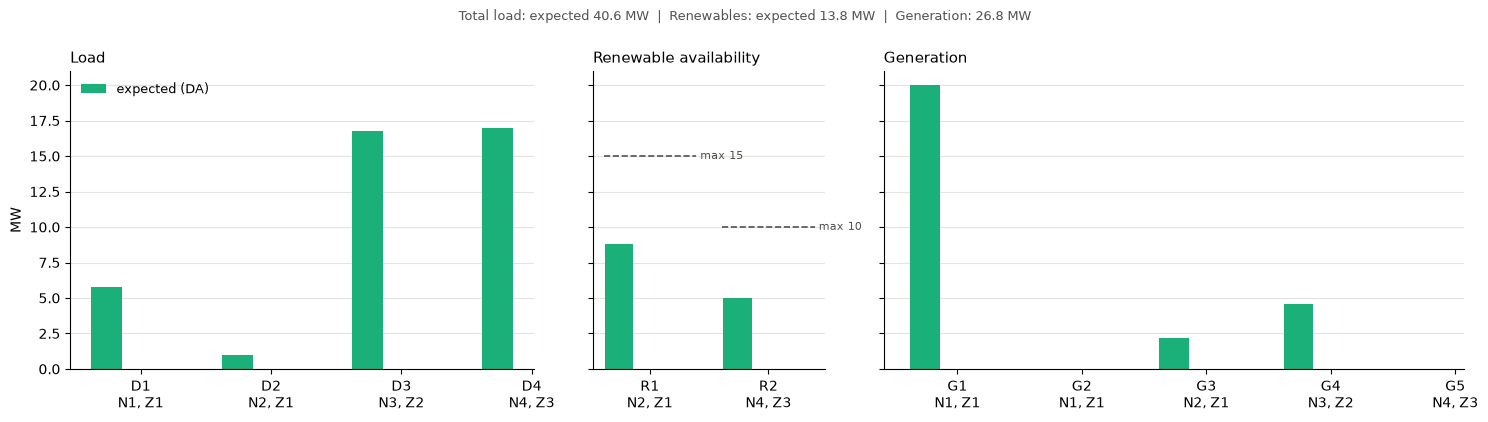

In [13]:
# --- Plot: load, renewable availability, and generation results for expected (DA) ---
cases = ['expected (DA)']  # Only include the expected case
colors = {'expected (DA)': '#1baf7a'}  # Color for the expected case
load_vals = data.expected_DA_load_vec[:, np.newaxis]  # Reshape to match expected format
res_vals = data.expected_DA_res_vec[:, np.newaxis]  # Reshape to match expected format
gen_vals = bc['g'].values[:, np.newaxis]  # Reshape generation results to match expected format

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True,
                         gridspec_kw=dict(width_ratios=[len(data.LOADS), len(data.RENEWABLES), len(data.GENERATORS)]))
panels = [(axes[0], data.LOADS, load_vals, data.node_of_load, 'Load'),
          (axes[1], data.RENEWABLES, res_vals, data.node_of_renewable, 'Renewable availability'),
          (axes[2], data.GENERATORS, gen_vals, data.node_of_generator, 'Generation')]
w = 0.26
for ax, units, vals, node_of, title in panels:
    x = np.arange(len(units))
    for j, case in enumerate(cases):
        label = case
        ax.bar(x + (j - 1) * w, vals[:, j], w * 0.92, color=colors[case], label=label, zorder=2)
    ax.set_xticks(x, [f"{u}\n{node_of[u]}, {data.node_zone[node_of[u]]}" for u in units])
    ax.set_title(title, loc='left', fontsize=11)
    ax.grid(axis='y', color='#e4e3df', zorder=0)
    ax.spines[['top', 'right']].set_visible(False)

# installed renewable capacity as a reference tick
for i, cap in enumerate(data.res_max_vec):
    axes[1].hlines(cap, i - 1.5 * w, i + 1.5 * w, colors='#52514e', linestyles='--', lw=1.2, zorder=3)
    axes[1].annotate(f"max {cap:g}", (i + 1.5 * w, cap), xytext=(3, 0), textcoords='offset points',
                     va='center', fontsize=8, color='#52514e')

axes[0].set_ylabel('MW')
axes[0].legend(frameon=False, fontsize=9, loc='upper left')
fig.suptitle(f"Total load: expected {load_vals.sum():.1f} MW  |  "
             f"Renewables: expected {res_vals.sum():.1f} MW  |  "
             f"Generation: {gen_vals.sum():.1f} MW", fontsize=9, color='#52514e', y=0.995)
fig.tight_layout()
plt.show()


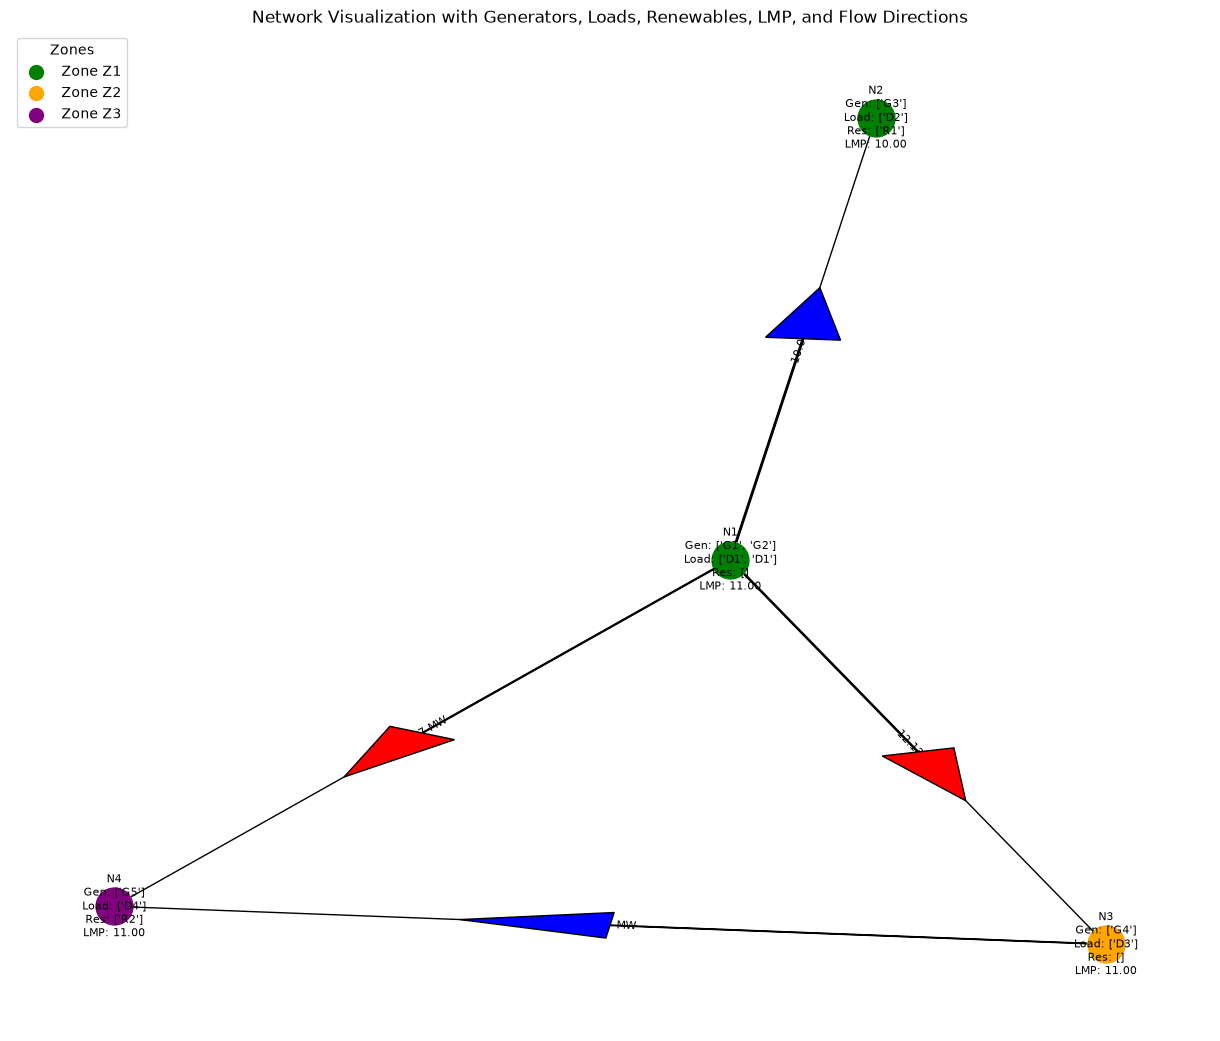

In [14]:
# Create a graph visualization with additional details
plt.figure(figsize=(12, 10))

# Draw the graph
pos = nx.spring_layout(G)  # Positioning for better visualization
nx.draw(G, pos, with_labels=False, node_color='lightblue', node_size=700, font_size=10, font_weight='bold')

# Add node labels with generators, loads, renewables, and LMP
detailed_labels = {
    node: f"{node}\nGen: {G.nodes[node].get('generators', [])}\nLoad: {G.nodes[node].get('loads', [])}\n"
          f"Res: {data.renewables_per_node.get(node, [])}\nLMP: {bc['LMP'].get(node, 'N/A'):.2f}"
    for node in G.nodes
}
nx.draw_networkx_labels(G, pos, labels=detailed_labels, font_size=8)

# Add edge labels for flow values and directions
edge_labels = {edge: f"{bc['f'].get(edge, 0):.2f} MW" for edge in G.edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)

# Add arrows to indicate flow direction
for edge in G.edges:
    flow = bc['f'].get(edge, 0)
    if flow != 0:
        start, end = pos[edge[0]], pos[edge[1]]
        direction = (end[0] - start[0], end[1] - start[1])
        plt.arrow(start[0], start[1], direction[0] * 0.5, direction[1] * 0.5,
                  head_width=0.05, head_length=0.1, fc='red' if flow > 0 else 'blue', ec='black')

# Create a zonal legend
zone_colors = {'Z1': 'green', 'Z2': 'orange', 'Z3': 'purple'}
for node, zone in data.nodes_per_zone.items():
    for n in zone:
        nx.draw_networkx_nodes(G, pos, nodelist=[n], node_color=zone_colors[node], node_size=700)

# Add legend for zones
for zone, color in zone_colors.items():
    plt.scatter([], [], c=color, label=f"Zone {zone}", s=100)
plt.legend(title="Zones", loc="upper left")

plt.title("Network Visualization with Generators, Loads, Renewables, LMP, and Flow Directions")
plt.show()